### Pytorchified version of previous code with linear layers and batch nomralization

In [1]:
words = open('names.txt').read().splitlines()
words[:3]

['emma', 'olivia', 'ava']

In [2]:
import torch
import matplotlib.pyplot as plt

In [3]:
# build vocabulary and mapping from characters to integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i + 1 for i , s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

In [4]:
# build dataset
# trigram dataset
block_size = 3
def build_dataset(words):
    X, y = [], []
    for word in words:
        context = [0] * block_size
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    y = torch.tensor(y)
    return X, y


In [5]:
# create test train dev splits
import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
X_tr, y_tr = build_dataset(words=words[:n1])
X_dev, y_dev = build_dataset(words=words[n1:n2])
X_te, y_te = build_dataset(words=words[n2:])

In [77]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        self.bias = bias
        # pytorch initializes weight as (fan_out, fan_in) and transposes on multiplication
        self.w = torch.randn((fan_in, fan_out)) #/  (fan_in ** 0.5) # kaiming He initializatoin
        self.b = torch.zeros(fan_out) if bias else None

    def __call__(self,x):
        self.out = x @ self.w 
        if self.b is not None:
            self.out += self.b
        return self.out

    def parameters(self):
        return [self.w] + ([] if self.b is None else [self.b])

class BatchNorm1D:
    def __init__(self, dim, eps = 1e-5, momentum = 0.1 ):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        self.gamma = torch.ones(dim) #batch_weight
        self.beta = torch.zeros(dim) # batch_bias
    
        # running buffer parametres
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    
    def __call__(self, x): # x.shape -> (n_batch, n_features)
        if self.training:
            x_mean = x.mean(0) # mean along batch dimension
            x_var = x.var(0, unbiased=False) # variance along batch dimension
        else:
            x_mean = self.running_mean
            x_var = self.running_var
        x_hat = (x - x_mean) / torch.sqrt(x_var + self.eps)
        self.out = x_hat * self.gamma + self.beta

        # update the buffers when training
        if self.training:
            self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * x_mean
            self.running_var = (1 - self.momentum) * self.running_var + self.momentum * x_var
        return self.out

    def parameters(self):
        return [self.gamma , self.beta]
    

    
class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []

In [78]:
# nn parameters
n_embed = 10 # dimensions of embedding space
n_hidden = 100 # no of neurons in hidden laer
vocab_size = len(stoi)

g = torch.Generator().manual_seed(123)

C = torch.randn((vocab_size, n_embed), generator=g)
layers = [
    Linear(n_embed * block_size, n_hidden),  Tanh(), 
    Linear(          n_hidden, n_hidden), Tanh(), 
    Linear(          n_hidden, n_hidden), Tanh(), 
    Linear(          n_hidden, n_hidden), Tanh(), 
    Linear(          n_hidden, n_hidden), Tanh(), 
    Linear(          n_hidden, vocab_size),
]

## initialization
with torch.no_grad():
    layers[-1].w *= 0.1
    if layers[-1].b is not None:
        layers[-1].b *= 0.0
    
    # multiply the weights of the hidden layers by 5/3 to compensate for the tanh's squashing nature nonlinearity
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.w *=  1 # 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
# print nuber of parameters
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

46497


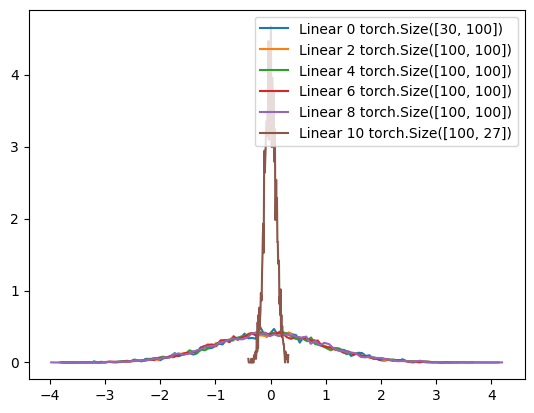

In [79]:
# plot the weights of the second layers as hitograms
# for every layer
legend = []

for i, layer in enumerate(layers):
    if isinstance(layer, Linear):
        hy, hx = torch.histogram(layer.w, density=True)
        # layer.w.shape
        # hx.shape, hy.shape

        plt.plot(hx[:-1].detach().numpy(), hy.detach().numpy())
        legend.append(f'Linear {i} {layer.w.shape}')
plt.legend(legend)

In [80]:
# optimization

max_steps = 200000
batch_size = 32
losses = []
for i in range(max_steps):
    # minibatch
    ix = torch.randint(0, X_tr.shape[0], (batch_size,))
    Xb, yb = X_tr[ix], y_tr[ix]

    # forward pass
    emb = C[Xb] # (32, 3, 10)
    x = emb.view(emb.shape[0], -1) # (32, 30)
    for layer in layers:
        x = layer(x)
    loss = torch.nn.functional.cross_entropy(x, yb)

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # retain gradients for non-leaf tensors remove after debugging during training

    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    losses.append(loss.item())
    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps} : {loss.item():.4f}')
    
    if i > 10000:
        break

      0/200000 : 3.3962
  10000/200000 : 2.4993


layer1 Tanh         mean:-0.0153   std:0.9863   saturation: 94.16%
layer3 Tanh         mean:-0.0181   std:0.9727   saturation: 88.56%
layer5 Tanh         mean:-0.0186   std:0.9655   saturation: 85.84%
layer7 Tanh         mean:0.0143   std:0.9580   saturation: 82.72%
layer9 Tanh         mean:0.0023   std:0.9565   saturation: 81.97%


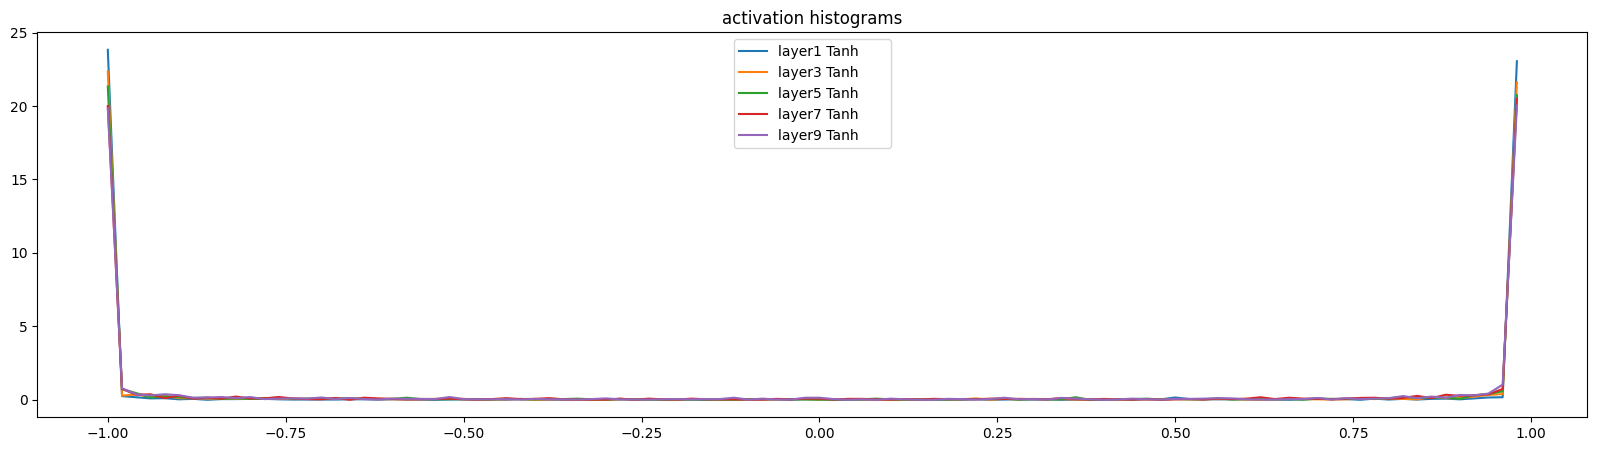

In [81]:
# visualize histograms
plt.figure(figsize=(20, 5))
legends = []
for i, layer in enumerate(layers[:-1]):
    if isinstance(layer, Tanh):
        t = layer.out
        print(f"layer{i} {layer.__class__.__name__:10s}   mean:{t.mean():.4f}   std:{t.std():.4f}   saturation: {(t.abs() > 0.97).float().mean() * 100:.2f}%")
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer{i} {layer.__class__.__name__:10s}')
plt.legend(legends)
plt.title('activation histograms');

layer1 Tanh      mean:-0.0012   std:0.0467
layer3 Tanh      mean:+0.0003   std:0.0208
layer5 Tanh      mean:+0.0000   std:0.0099
layer7 Tanh      mean:-0.0000   std:0.0047
layer9 Tanh      mean:+0.0001   std:0.0019


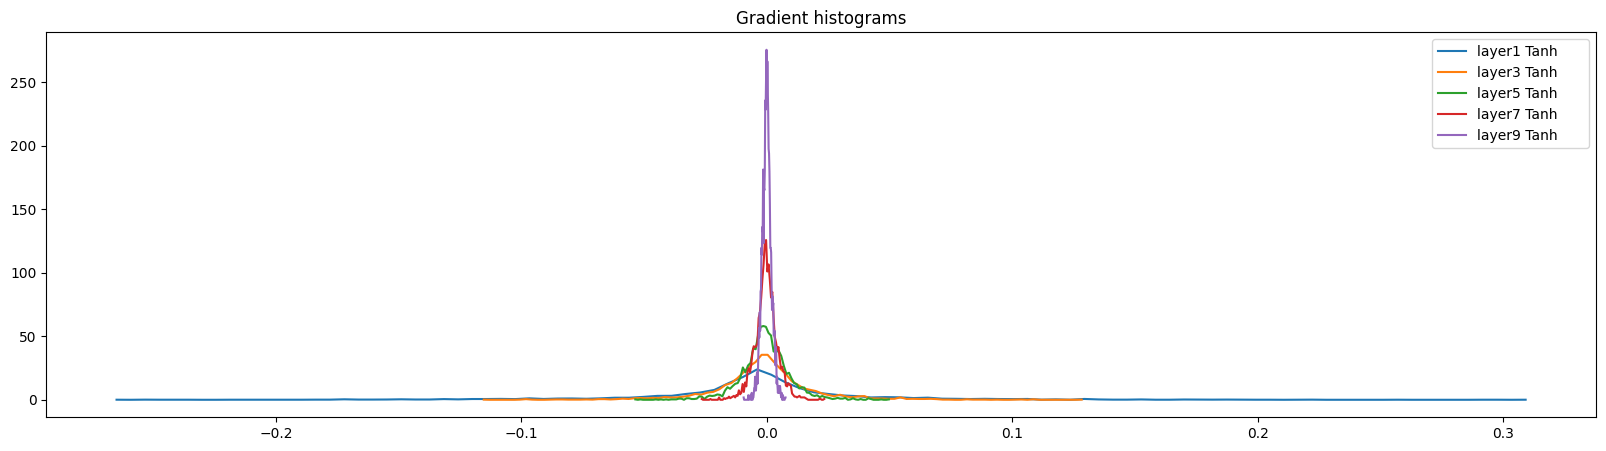

In [82]:
# visualize histograms but for gradients
plt.figure(figsize=(20, 5))
legends = []
for i, layer in enumerate(layers[:-1]):
    if isinstance(layer, Tanh):
        t = layer.out.grad
        print(f"layer{i} {layer.__class__.__name__:7s}   mean:{t.mean():+.4f}   std:{t.std():.4f}")
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer{i} {layer.__class__.__name__:10s}')
plt.legend(legends)
plt.title('Gradient histograms');

In [86]:
def test():
    ix = torch.randint(0, X_tr.shape[0], (batch_size,))
    Xb, yb = X_tr[ix], y_tr[ix]
    print('Xb', Xb.shape)
    print('yb', yb.shape)
    # print('Xb', Xb)
    # print('yb', yb)
    print('emb', C[Xb].shape)
    print('emb', C[Xb][:, :1])  # Print first 5 columns of the embedding
test()

Xb torch.Size([32, 3])
yb torch.Size([32])
emb torch.Size([32, 3, 10])
emb tensor([[[-5.4376e-01, -4.6993e+00,  3.7442e+00, -5.8547e+00, -1.7169e+00,
          -4.1991e+00, -6.2828e+00, -2.8081e+00, -1.1132e+00,  2.0538e+00]],

        [[-3.6750e-01,  1.7638e+00,  3.5060e+00,  9.9229e-01,  9.4726e-01,
           2.9359e+00,  4.8892e-01,  5.0665e+00,  2.5420e+00, -2.9054e+00]],

        [[-5.4376e-01, -4.6993e+00,  3.7442e+00, -5.8547e+00, -1.7169e+00,
          -4.1991e+00, -6.2828e+00, -2.8081e+00, -1.1132e+00,  2.0538e+00]],

        [[-4.0859e+00, -6.6444e-01, -5.6400e+00,  1.3366e+00,  4.3880e+00,
           1.2216e+00,  1.1716e+00, -6.9538e+00, -5.4262e+00,  1.8865e+00]],

        [[-3.6750e-01,  1.7638e+00,  3.5060e+00,  9.9229e-01,  9.4726e-01,
           2.9359e+00,  4.8892e-01,  5.0665e+00,  2.5420e+00, -2.9054e+00]],

        [[ 6.8532e-01,  7.3015e-02,  1.3703e+00,  5.3528e-01,  1.0890e+00,
          -3.5842e-01, -1.7329e+00, -8.4001e-01, -1.4905e+00, -2.0554e+00]],

       